# Previsão da resistência à compressão do concreto

**Objetivo:** prever a resistência à compressão do concreto (em MPa) a partir da composição do traço e da idade de cura.

**Por que importa:** o ensaio de resistência leva dias (7, 28 dias ou mais). Um modelo que estima a resistência pelo traço permite ajustar a mistura antes, reduzindo retrabalho e desperdício de material na obra.

**Dados:** [Concrete Compressive Strength (Kaggle)](https://www.kaggle.com/datasets/elikplim/concrete-compressive-strength-data-set), originalmente do repositório UCI: 1.030 traços, 8 variáveis de entrada e 1 alvo.

| Variável | Unidade |
|---|---|
| cement, blast_furnace_slag, fly_ash, water, superplasticizer, coarse_aggregate, fine_aggregate | kg/m³ |
| age | dias |
| concrete_compressive_strength (**alvo**) | MPa |

## 1. Carregando os dados

In [1]:
import numpy as np
import pandas as pd

In [2]:
df= pd.read_csv('/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv')

## 2. Primeira olhada

Início e fim da tabela, estatísticas de cada coluna e tipos de dado.

In [3]:
df.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [4]:
df.tail()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77
1029,260.9,100.5,78.3,200.6,8.6,864.5,761.5,28,32.40


In [5]:
df.describe()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1030 non-null   float64
 1   blast_furnace_slag             1030 non-null   float64
 2   fly_ash                        1030 non-null   float64
 3   water                          1030 non-null   float64
 4   superplasticizer               1030 non-null   float64
 5   coarse_aggregate               1030 non-null   float64
 6   fine_aggregate                 1030 non-null   float64
 7   age                            1030 non-null   int64  
 8   concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


## 3. Qualidade dos dados

**Duplicados:** 25 linhas são cópias exatas de outras: três traços diferentes, dois deles repetidos em várias idades. Se ficassem, o modelo daria peso extra a esses traços e o teste poderia conter linhas que ele já viu no treino.

In [7]:
df.duplicated().sum()


np.int64(25)

In [8]:
df[df.duplicated()]


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
77,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
80,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
100,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
103,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
123,425.0,106.3,0.0,153.5,16.5,852.1,887.1,28,60.29


In [9]:
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.69
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.69
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.30


In [10]:
df = df.drop_duplicates()

In [11]:
df.duplicated().sum() 

np.int64(0)

**Nulos e valores impossíveis:** nenhum nulo e nenhum valor negativo.

**Checagem de domínio:** não basta o dado ser "válido", ele precisa fazer sentido físico. A idade vai de 1 a 365 dias e o cimento de 102 a 540 kg/m³, faixas plausíveis para concreto. Não há idade 0 nem consumo de cimento absurdo.

In [12]:
df.isnull().sum()

cement                           0
blast_furnace_slag               0
fly_ash                          0
water                            0
superplasticizer                 0
coarse_aggregate                 0
fine_aggregate                   0
age                              0
concrete_compressive_strength    0
dtype: int64

In [13]:
(df < 0).sum()

cement                           0
blast_furnace_slag               0
fly_ash                          0
water                            0
superplasticizer                 0
coarse_aggregate                 0
fine_aggregate                   0
age                              0
concrete_compressive_strength    0
dtype: int64

In [14]:
print(df['age'].min(), df['age'].max())
print(df['cement'].min(), df['cement'].max())

1 365
102.0 540.0


## 4. Análise exploratória: o que se relaciona com a resistência?

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

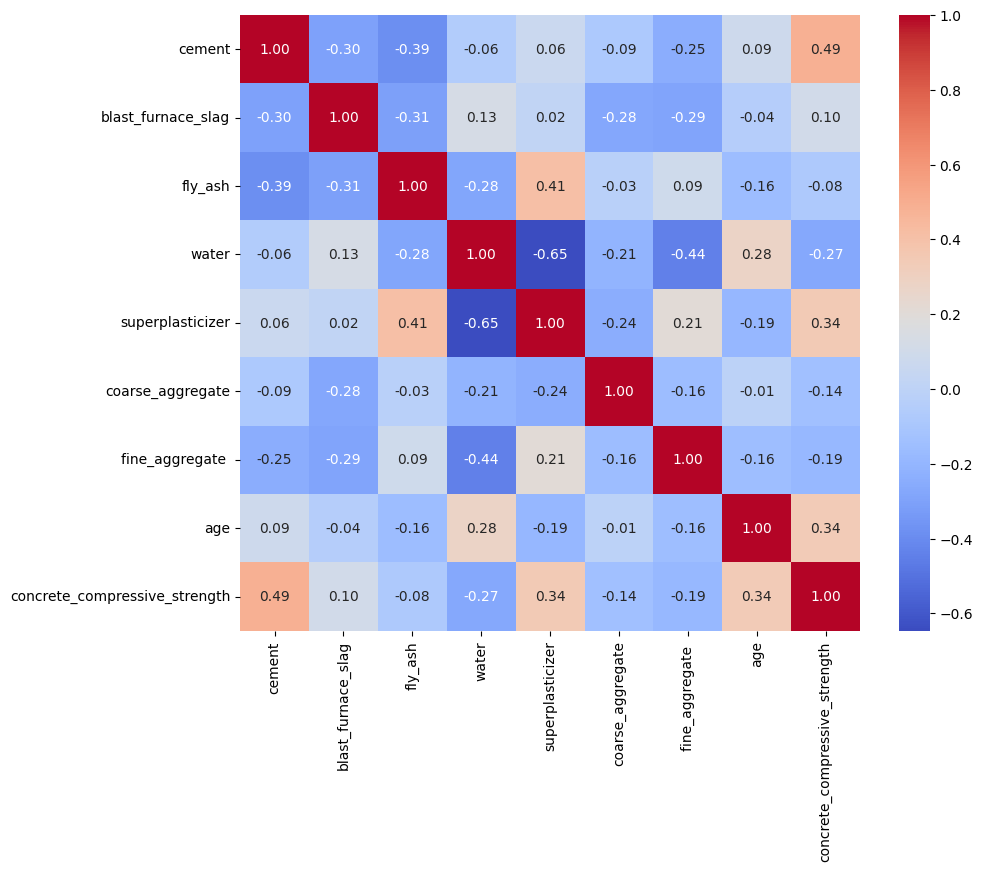

In [16]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

Ranking da correlação de cada variável com a resistência:

In [17]:
df.corr()['concrete_compressive_strength'].sort_values(ascending=False) 

concrete_compressive_strength    1.000000
cement                           0.488283
superplasticizer                 0.344209
age                              0.337367
blast_furnace_slag               0.103374
fly_ash                         -0.080648
coarse_aggregate                -0.144717
fine_aggregate                  -0.186448
water                           -0.269624
Name: concrete_compressive_strength, dtype: float64

**Leitura de engenharia:**

- **Cimento (0,49):** a relação positiva mais forte da tabela. Mais cimento tende a dar mais resistência, mas sozinho ele não explica tudo.
- **Superplastificante (+0,34)** e **idade (+0,34)** vêm em seguida: o aditivo permite usar menos água, e o concreto ganha resistência com o tempo de cura.
- **Água (−0,27)** é negativa: quanto mais aguado o traço, mais fraco (a relação água/cimento que todo engenheiro conhece).

Agora, os pares de variáveis correlacionados **entre si** (multicolinearidade), que é uma pergunta diferente:

In [18]:
import itertools

colunas = df.corr().columns
pares = list(itertools.combinations(colunas, 2))  # combinations já evita repetir o par espelhado

resultado = [(c1, c2, df[c1].corr(df[c2])) for c1, c2 in pares]
corr_df = pd.DataFrame(resultado, columns=['var1', 'var2', 'correlacao'])
corr_df.reindex(corr_df['correlacao'].abs().sort_values(ascending=False).index).head(10)

,var1,var2,correlacao
21,water,superplasticizer,-0.646946
7,cement,concrete_compressive_strength,0.488283
23,water,fine_aggregate,-0.444915
16,fly_ash,superplasticizer,0.414213
1,cement,fly_ash,-0.385610
29,superplasticizer,concrete_compressive_strength,0.344209
35,age,concrete_compressive_strength,0.337367
8,blast_furnace_slag,fly_ash,-0.312352
0,cement,blast_furnace_slag,-0.303324
12,blast_furnace_slag,fine_aggregate,-0.289685


O par mais forte é **água × superplastificante (−0,65)**: faz sentido, porque o superplastificante existe justamente para reduzir a água do traço. Nenhuma correlação entre variáveis é tão alta a ponto de exigir remover colunas.

## 5. Modelagem

**Separação treino/teste:** 80% dos traços para treinar e 20% guardados para avaliar, como uma prova que o modelo nunca viu.

In [19]:
from sklearn.model_selection import train_test_split

X = df.drop('concrete_compressive_strength', axis=1)
y = df['concrete_compressive_strength']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

**Baseline:** antes de qualquer modelo, uma régua mínima. O `DummyRegressor` ignora o traço e sempre "chuta" a mediana da resistência. É como um engenheiro que, sem olhar o traço, diz que todo concreto vai dar ~34 MPa. Se o modelo não for bem melhor que esse chute, ele não serve.

In [20]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline = DummyRegressor(strategy='median')
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)

mae_base = mean_absolute_error(y_test, pred_baseline)
rmse_base = np.sqrt(mean_squared_error(y_test, pred_baseline))
r2_base = r2_score(y_test, pred_baseline)

print(f"Baseline -> MAE: {mae_base:.2f} | RMSE: {rmse_base:.2f} | R²: {r2_base:.2f}")

Baseline -> MAE: 13.97 | RMSE: 17.42 | R²: -0.02


**Modelos comparados:**

- **Regressão Linear** e **KNN** recebem os dados em escala (`StandardScaler`), porque usam coeficientes e distâncias, e uma variável em kg/m³ não pode pesar mais só por ter números maiores.
- **Random Forest** usa os dados originais: árvores só fazem perguntas de "maior ou menor que", então a escala não muda nada.

Métricas: **MAE** (erro médio, em MPa), **RMSE** (pune mais os erros grandes) e **R²** (quanto da variação da resistência o modelo explica).

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modelos = {
    "Regressão Linear": (LinearRegression(), X_train_scaled, X_test_scaled),
    "Random Forest":    (RandomForestRegressor(random_state=42), X_train, X_test),
    "KNN":              (KNeighborsRegressor(), X_train_scaled, X_test_scaled),
}

resultados = {"Baseline (Dummy)": {"MAE": mae_base, "RMSE": rmse_base, "R2": r2_base}}

for nome, (modelo, X_tr, X_te) in modelos.items():
    modelo.fit(X_tr, y_train)
    pred = modelo.predict(X_te)
    resultados[nome] = {
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    }

pd.DataFrame(resultados).T

,MAE,RMSE,R2
Baseline (Dummy),13.973632,17.417243,-0.016879
Regressão Linear,8.895256,11.191320,0.580170
Random Forest,3.497868,5.255221,0.907425
KNN,7.125303,9.192324,0.716756


**Resultado:**

| Modelo | MAE (MPa) | RMSE (MPa) | R² |
|---|---|---|---|
| Baseline (mediana) | 13,97 | 17,42 | −0,02 |
| Regressão Linear | 8,90 | 11,19 | 0,58 |
| KNN | 7,13 | 9,19 | 0,72 |
| **Random Forest** | **3,50** | **5,26** | **0,91** |

A Regressão Linear melhora o baseline, mas fica em R² 0,58: a relação entre traço, idade e resistência não é uma reta: em parte porque o ganho de resistência com a idade, por exemplo, desacelera com o tempo. O Random Forest captura essas curvas e interações e reduz o erro médio em 4 vezes em relação ao baseline.

## Conclusão

Com o traço em mãos, dá para estimar a resistência do concreto antes do ensaio, com erro médio de ~3,5 MPa. Isso antecipa a decisão: ganha prazo de obra, evita retrabalho e, sem superdimensionar a mistura, economiza cimento, um dos insumos mais caros do traço. O modelo não substitui o ensaio, que segue obrigatório.

O Random Forest foi o melhor modelo: explica 91% da variação da resistência (R² 0,91), enquanto o chute pela mediana erra em média ~14 MPa. Cimento, idade e superplastificante são os fatores mais ligados à resistência.

**Próximos passos (v2):** ajuste de hiperparâmetros com `GridSearchCV`, validação cruzada para confirmar a estabilidade do R² e gráfico de importância das variáveis.